# Phase 3 — How long will this order take?

**Question.** At checkout, before anything has shipped, how many days will this order take to arrive, and how
sure can we be?

**Why quantiles.** A promise is a commitment with an implied on-time rate. If the model predicts each order's
90th percentile delivery time, promising that date should be kept for about 90% of orders. So instead of one
number, the model predicts nine quantiles (P50 to P97.5). Phase 4 turns them into promises.

**Set-up**

| | |
|---|---|
| Label | calendar days from purchase to delivery (the unit a promise is made in) |
| Features | 29 checkout-time features from `marts.fct_order_features`: route, distance, basket, Olist's own estimate, the seller's track record *as of checkout*, and network congestion over the previous days |
| Leakage guards | dbt unit test + two singular tests: seller history only counts orders delivered before checkout, congestion only counts earlier days |
| Split (by purchase date) | train Jan–Dec 2017 · calibrate Jan 2018 · **test Feb–Aug 2018** (includes the Feb–Mar 2018 disruption) |
| Model | LightGBM quantile regression on log(1 + days), one model per quantile, early-stopped on the calibration month |
| Calibration | split-conformal offset per quantile, fitted on the calibration month |
| Orders never delivered | kept in calibration and test, counted as missed promises |

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "analysis"))
import predict as P  # noqa: E402

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
DB = str(ROOT / "warehouse" / "olist.duckdb")
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Data and split

In [2]:
df = P.load(DB)
train, calib, test = (df[df.split == s].reset_index(drop=True) for s in ["train", "calib", "test"])
pd.DataFrame({
    "orders": df.groupby("split").size(),
    "never delivered": df.groupby("split").censored.sum(),
    "median days": df.groupby("split").delivery_days.median(),
    "Olist on-time rate": pd.Series({s: P.olist_reference(d)["on_time_rate"] for s, d in
                                    [("train", train), ("calib", calib), ("test", test)]}),
}).loc[["train", "calib", "test"]]

,orders,never delivered,median days,Olist on-time rate
train,43937,530,11.000,0.932
calib,7143,74,12.000,0.933
test,46036,493,9.000,0.910


The test period is harder than anything in training: the Feb–Mar 2018 disruption pushed Olist's own on-time
rate down to 80–85%, and then deliveries got much *faster* from June onwards.

## 2. Models

In [3]:
models = P.fit_quantile_models(train, calib)
pred_calib = P.predict_quantiles(models, calib)
pred_test = P.predict_quantiles(models, test)
offsets = P.conformal_offsets(np.log1p(pred_calib), calib.delivery_days.to_numpy(float), calib.censored.to_numpy())
pred_test_cal = P.apply_offsets(pred_test, offsets)

# Baseline: historical delivery-time quantiles per seller-state -> customer-state route, same conformal step.
base_calib = P.route_baseline(train, calib)
base_test = P.route_baseline(train, test)
base_off = P.conformal_offsets(np.log1p(base_calib), calib.delivery_days.to_numpy(float), calib.censored.to_numpy())
base_test_cal = P.apply_offsets(base_test, base_off)

pd.DataFrame({"boosting rounds": [models[q].best_iteration for q in P.QUANTILES],
              "conformal offset (log days)": offsets}, index=pd.Index(P.QUANTILES, name="quantile")).T

quantile,0.500,0.600,0.700,0.800,0.850,0.900,0.925,0.950,0.975
boosting rounds,149.000,202.000,130.000,929.000,278.000,234.000,461.000,242.000,172.000
conformal offset (log days),-0.108,-0.094,-0.082,-0.052,-0.049,-0.015,0.010,0.046,0.176


## 3. Are the quantiles honest? (test set)

In [4]:
methods = {
    "route quantiles + conformal": base_test_cal,
    "LightGBM": pred_test,
    "LightGBM + conformal": pred_test_cal,
}
tab = P.coverage_table(test, methods)
cov = tab.pivot(index="quantile", columns="method", values="on_time_rate")
cov

method,LightGBM,LightGBM + conformal,route quantiles + conformal
quantile,,,
0.500,0.697,0.620,0.682
0.600,0.755,0.699,0.742
0.700,0.817,0.776,0.802
0.800,0.860,0.839,0.870
0.850,0.896,0.880,0.899
0.900,0.922,0.918,0.929
0.925,0.933,0.935,0.945
0.950,0.950,0.956,0.963
0.975,0.967,0.979,0.982


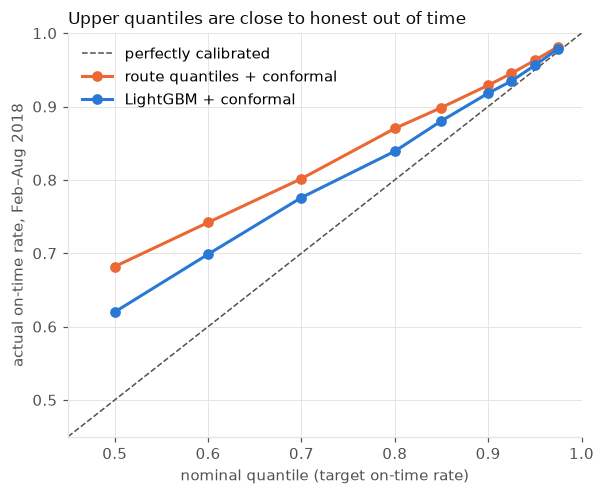

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot([0.45, 1], [0.45, 1], color=INK2, lw=1, ls="--", label="perfectly calibrated")
ax.plot(cov.index, cov["route quantiles + conformal"], color=ORANGE, lw=2, marker="o", ms=6,
        label="route quantiles + conformal")
ax.plot(cov.index, cov["LightGBM + conformal"], color=BLUE, lw=2, marker="o", ms=6, label="LightGBM + conformal")
ax.set_xlabel("nominal quantile (target on-time rate)")
ax.set_ylabel("actual on-time rate, Feb–Aug 2018")
ax.set_title("Upper quantiles are close to honest out of time", loc="left", fontsize=11)
ax.set_xlim(0.45, 1)
ax.set_ylim(0.45, 1)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "03_quantile_calibration.png", bbox_inches="tight")

In the range where a promise would actually be set (P85–P97.5), the calibrated model keeps its promises at
or slightly above the target rate: 91.8% for P90 and 95.6% for P95. It errs on the safe side by 0.4–3.0
points. Lower quantiles over-cover by more, because the test period was faster than January, but promises are
set from the upper tail.

## 4. Sharper promises at the same reliability

A good promise model keeps the same share of promises with *shorter* promises. Each curve traces
the trade-off as the quantile goes from P50 to P97.5; the dot is what Olist actually promised.

,avg promise at Olist's on-time rate (days),vs Olist (days)
Olist,22.912,0.000
route quantiles + conformal,22.162,-0.750
LightGBM + conformal,20.917,-1.995


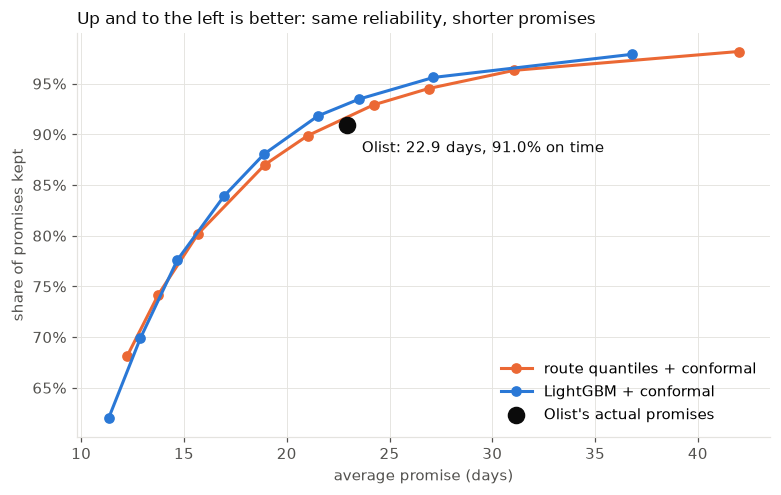

In [6]:
olist = P.olist_reference(test)
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for name, color in [("route quantiles + conformal", ORANGE), ("LightGBM + conformal", BLUE)]:
    t = tab[tab.method == name]
    ax.plot(t.avg_promise_days, t.on_time_rate, color=color, lw=2, marker="o", ms=6, label=name)
ax.scatter([olist["avg_promise_days"]], [olist["on_time_rate"]], s=110, color=INK, zorder=5,
           label="Olist's actual promises")
ax.annotate(f"Olist: {olist['avg_promise_days']:.1f} days, {olist['on_time_rate']:.1%} on time",
            (olist["avg_promise_days"], olist["on_time_rate"]), xytext=(10, -18), textcoords="offset points", color=INK)
ax.set_xlabel("average promise (days)")
ax.set_ylabel("share of promises kept")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Up and to the left is better: same reliability, shorter promises", loc="left", fontsize=11)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "03_promise_frontier.png", bbox_inches="tight")

def promise_at(t, rate):
    return float(np.interp(rate, t.on_time_rate, t.avg_promise_days))

target = olist["on_time_rate"]
summary = pd.DataFrame({
    "avg promise at Olist's on-time rate (days)": {
        "Olist": olist["avg_promise_days"],
        "route quantiles + conformal": promise_at(tab[tab.method == "route quantiles + conformal"], target),
        "LightGBM + conformal": promise_at(tab[tab.method == "LightGBM + conformal"], target),
    }
})
summary["vs Olist (days)"] = summary.iloc[:, 0] - olist["avg_promise_days"]
summary

Matched to Olist's on-time rate in the test period (91.0%), the calibrated model promises **2.0 days less on
average (20.9 vs 22.9 days, −9%)**. A simple per-route rule recovers only 0.75 days of that. Phase 4 explores the whole frontier: how much
shorter promises could be at each late-rate target, and what the Phase 2 review costs say about where to sit
on it.

## 5. What happens in a disruption?

On-time rate by purchase month for the calibrated P90 promise versus Olist's promise.

In [7]:
j = P.QUANTILES.index(0.9)
t = test.assign(
    month=test.purchase_date.dt.strftime("%Y-%m"),
    olist_kept=P.kept(test.promised_days.to_numpy(float), test),
    model_promise=P.promise_days(pred_test_cal[:, j]),
)
t["model_kept"] = P.kept(t.model_promise.to_numpy(), t)
monthly = t.groupby("month").agg(olist_on_time=("olist_kept", "mean"), model_on_time=("model_kept", "mean"),
                                 olist_promise=("promised_days", "mean"), model_promise=("model_promise", "mean"))
monthly

,olist_on_time,model_on_time,olist_promise,model_promise
month,,,,
2018-02,0.851,0.850,25.171,23.954
2018-03,0.795,0.830,22.743,23.730
2018-04,0.941,0.953,24.347,23.709
2018-05,0.927,0.931,23.514,22.262
2018-06,0.981,0.973,28.408,21.553
2018-07,0.957,0.943,20.338,17.470
2018-08,0.931,0.961,15.785,17.235


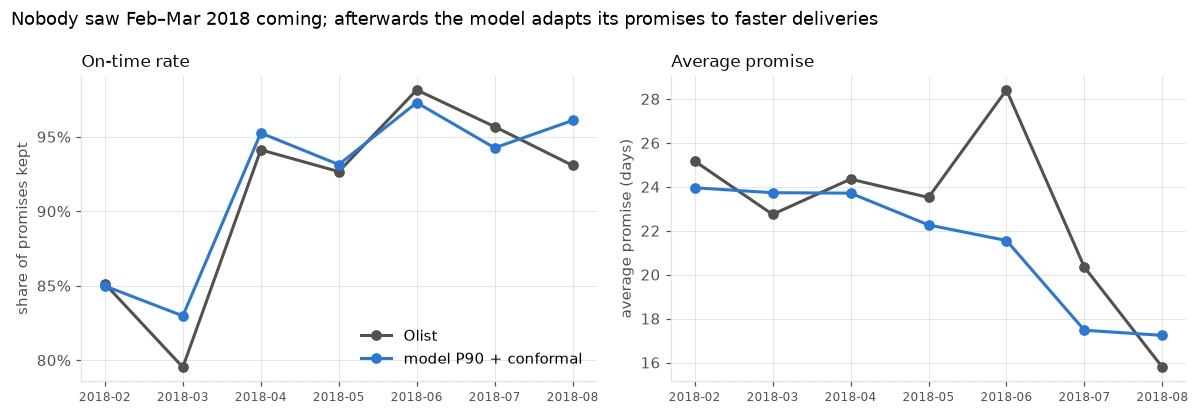

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(monthly))
for ax, (a, b, ylab, title) in zip(axes, [
    ("olist_on_time", "model_on_time", "share of promises kept", "On-time rate"),
    ("olist_promise", "model_promise", "average promise (days)", "Average promise"),
], strict=True):
    ax.plot(x, monthly[a], color=INK2, lw=2, marker="o", ms=6, label="Olist")
    ax.plot(x, monthly[b], color=BLUE, lw=2, marker="o", ms=6, label="model P90 + conformal")
    ax.set_xticks(x, monthly.index, rotation=0, fontsize=8)
    ax.set_ylabel(ylab)
    ax.set_title(title, loc="left", fontsize=11)
axes[0].yaxis.set_major_locator(plt.MultipleLocator(0.05))
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].legend(loc="lower right")
fig.suptitle("Nobody saw Feb–Mar 2018 coming; afterwards the model adapts its promises to faster deliveries",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "03_monthly_on_time.png", bbox_inches="tight")

Both Olist and the model miss far more promises in February and March 2018. The congestion features
help a little in March, but a disruption that has not shown up in completed deliveries yet cannot be seen at
checkout. Two production consequences follow:
* **Recalibrate often.** The conformal offset is a single number per quantile, cheap to refresh weekly from
  recently delivered orders.
* **Monitor the on-time rate as it happens** and widen promises when it drops, rather than waiting for reviews.

Once deliveries speed up, the model follows them. In June–July its promises are 3–7 days shorter than Olist's
(21.5 vs 28.4 days, then 17.4 vs 20.3) while 94–97% are kept. In August, Olist cut its promises sharply to 15.8
days and kept only 93%; the model promised 17.2 days and kept 96%.

## 6. P(late) for a given promise

Phase 4 needs, for any candidate promise, the probability that this order misses it. Reading the predicted
quantile function at Olist's actual promise gives a testable version: is P(late) calibrated?

In [9]:
p_late = P.prob_late(pred_test_cal, test.promised_days.to_numpy(float))
late = ~P.kept(test.promised_days.to_numpy(float), test)
rel = (pd.DataFrame({"p": p_late, "late": late})
         .assign(bin=lambda d: pd.qcut(d.p.rank(method="first"), 10, labels=False))
         .groupby("bin").agg(predicted=("p", "mean"), actual=("late", "mean"), orders=("late", "size")))
print(f"AUC {roc_auc_score(late, p_late):.3f}   Brier {brier_score_loss(late, p_late):.4f}   "
      f"(always predicting the average: {brier_score_loss(late, np.full(len(late), late.mean())):.4f})")
rel

AUC 0.737   Brier 0.0780   (always predicting the average: 0.0823)


,predicted,actual,orders
bin,,,
0,0.029,0.015,4604
1,0.041,0.023,4604
2,0.048,0.036,4603
3,0.058,0.050,4604
4,0.070,0.062,4603
5,0.086,0.075,4604
6,0.109,0.093,4603
7,0.141,0.118,4604
8,0.193,0.165,4603


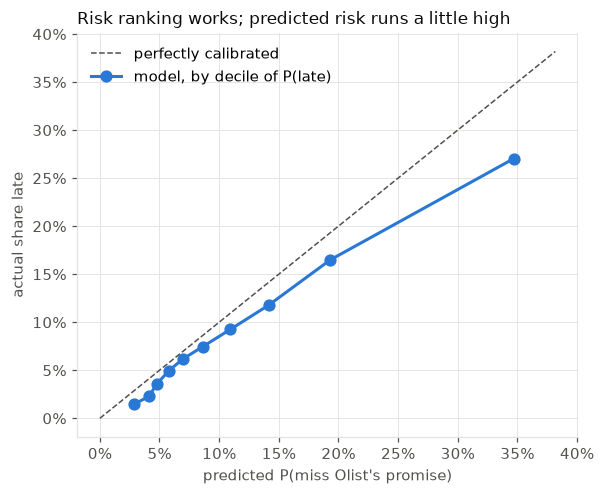

In [10]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
lim = max(rel.predicted.max(), rel.actual.max()) * 1.1
ax.plot([0, lim], [0, lim], color=INK2, lw=1, ls="--", label="perfectly calibrated")
ax.plot(rel.predicted, rel.actual, color=BLUE, lw=2, marker="o", ms=7, label="model, by decile of P(late)")
ax.set_xlabel("predicted P(miss Olist's promise)")
ax.set_ylabel("actual share late")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Risk ranking works; predicted risk runs a little high", loc="left", fontsize=11)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "03_p_late_reliability.png", bbox_inches="tight")

The model separates risky orders from safe ones (AUC 0.74; the riskiest tenth is late 27% of the time against
1.5% for the safest tenth). The levels run high (35% predicted vs 27% actual for the riskiest tenth) because
deliveries sped up after the calibration month, the same drift seen in section 3. Phase 4 uses P(late) to *rank* orders, and re-fitting the
conformal offsets on recent deliveries would correct the level.

## 7. What drives the prediction?

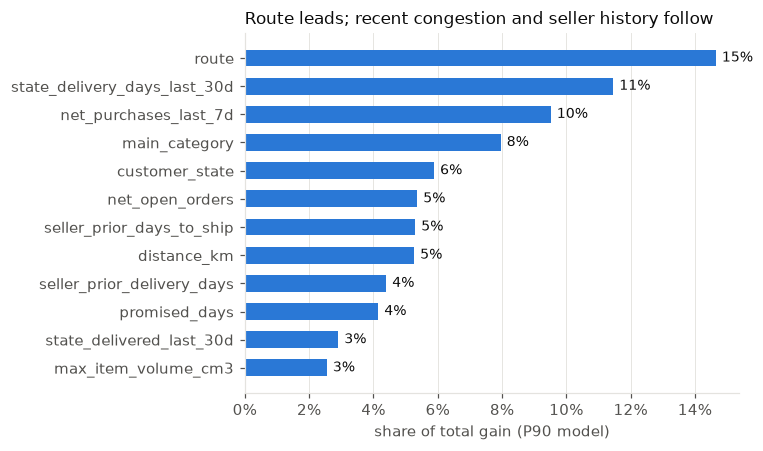

In [11]:
imp = pd.Series(models[0.9].feature_importance("gain"), index=P.FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
for yi, v in enumerate(imp.values):
    ax.annotate(f"{v:.0%}", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("share of total gain (P90 model)")
ax.set_title("Route leads; recent congestion and seller history follow", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "03_feature_importance.png", bbox_inches="tight")

## 8. Takeaways

* **Calibrated quantiles work where it matters.** Out of time, P85–P97.5 promises are kept at or slightly above
  their nominal rate, counting never-delivered orders as misses.
* **Shorter promises at equal reliability.** At Olist's own test-period on-time rate (91%), the model promises
  2.0 days less on average (−9%). Phase 4 maps the full frontier.
* **No model sees a disruption before it shows up in the data.** The fix is operational: refresh the
  conformal offsets weekly and monitor on-time rates live.
* **About 1% of orders are never delivered**, which caps any promise's achievable on-time rate at about 99%.

**Carried forward to Phase 4:** calibrated quantile predictions for the calibration and test months, saved
to `warehouse/phase3_predictions.parquet` (git-ignored).

In [12]:
cols = ["order_id", "split", "purchase_date", "delivery_days", "censored", "promised_days",
        "customer_state", "route", "main_category"]
out_frames = []
for frame, pred in [(calib, P.apply_offsets(pred_calib, offsets)), (test, pred_test_cal)]:
    q = pd.DataFrame(pred, columns=[f"q{int(round(x * 1000)):03d}" for x in P.QUANTILES])
    out_frames.append(pd.concat([frame[cols].reset_index(drop=True), q], axis=1))
preds = pd.concat(out_frames, ignore_index=True)
preds.to_parquet(ROOT / "warehouse" / "phase3_predictions.parquet", index=False)
tab.to_csv(ROOT / "docs" / "phase3_coverage.csv", index=False)
print(preds.shape)
preds.head(3)

(53179, 18)


,order_id,split,purchase_date,delivery_days,censored,promised_days,customer_state,route,main_category,q500,q600,q700,q800,q850,q900,q925,q950,q975
0,4f6daad34df49e10c8072b33faafcb2a,calib,2018-01-01,29,False,35,AL,SP>AL,pet_shop,20.840,23.706,26.037,27.271,31.117,32.419,33.302,38.104,53.346
1,0462bad26ccfb8508951beb9ea398ae1,calib,2018-01-01,22,False,39,ES,SP>ES,baby,14.837,17.358,18.088,21.994,23.833,25.280,30.136,34.863,47.957
2,fbe41a4974e4a492e085d90e5be0b3e3,calib,2018-01-01,4,False,28,SP,SP>SP,sports_leisure,7.229,7.819,9.310,10.875,13.424,16.794,17.793,19.239,26.086
